<a href="https://colab.research.google.com/github/2000Voli/2000Voli/blob/main/Projeto_integrado_Feature_Engineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [39]:

import pandas as pd

# Base oficial do Projeto Integrado
url = "https://raw.githubusercontent.com/diogenesjusto/FIAP/refs/heads/master/dados/credit_features_formatado.csv"

df = pd.read_csv(url)

# Verificar dimensões e primeiras linhas
print("Dimensões:", df.shape)
display(df.head())


Dimensões: (50000, 55)


/tmp/ipykernel_2591/2542752005.py:6: DtypeWarning: Columns (52,53) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(url)


,Unnamed: 0,ID_CLIENTE,TIPO_FUNCIONARIO,DIA_PAGAMENTO,TIPO_ENVIO_APLICACAO,QUANT_CARTOES_ADICIONAIS,TIPO_ENDERECO_POSTAL,SEXO,ESTADO_CIVIL,QUANT_DEPENDENTES,NIVEL_EDUCACIONAL,ESTADO_NASCIMENTO,CIDADE_NASCIMENTO,NACIONALIDADE,ESTADO_RESIDENCIAL,CIDADE_RESIDENCIAL,BAIRRO_RESIDENCIAL,FLAG_TELEFONE_RESIDENCIAL,CODIGO_AREA_TELEFONE_RESIDENCIAL,TIPO_RESIDENCIA,MESES_RESIDENCIA,FLAG_TELEFONE_MOVEL,FLAG_EMAIL,RENDA_PESSOAL_MENSAL,OUTRAS_RENDAS,FLAG_VISA,FLAG_MASTERCARD,FLAG_DINERS,FLAG_AMERICAN_EXPRESS,FLAG_OUTROS_CARTOES,QUANT_CONTAS_BANCARIAS,QUANT_CONTAS_BANCARIAS_ESPECIAIS,VALOR_PATRIMONIO_PESSOAL,QUANT_CARROS,EMPRESA,ESTADO_PROFISSIONAL,CIDADE_PROFISSIONAL,BAIRRO_PROFISSIONAL,FLAG_TELEFONE_PROFISSIONAL,CODIGO_AREA_TELEFONE_PROFISSIONAL,MESES_NO_TRABALHO,CODIGO_PROFISSAO,TIPO_OCUPACAO,CODIGO_PROFISSAO_CONJUGE,NIVEL_EDUCACIONAL_CONJUGE,FLAG_DOCUMENTO_RESIDENCIAL,FLAG_RG,FLAG_CPF,FLAG_COMPROVANTE_RENDA,PRODUTO,FLAG_REGISTRO_ACSP,IDADE,CEP_RESIDENCIAL_3,CEP_PROFISSIONAL_3,ROTULO_ALVO_MAU=1
0,0,1,C,5,Web,0,1,F,6,1,0,RN,Assu,1,RN,Santana do Matos,Centro,Y,105,1.00,15.00,N,1,900.00,0.00,1,1,0,0,0,0,0,0.00,0,N,,NaN,NaN,N,,0,9.00,4.00,NaN,NaN,0,0,0,0,1,N,32,595,595,1
1,1,2,C,15,Carga,0,1,F,2,0,0,RJ,rio de janeiro,1,RJ,RIO DE JANEIRO,CAMPO GRANDE,Y,20,1.00,1.00,N,1,750.00,0.00,0,0,0,0,0,0,0,0.00,0,Y,,NaN,NaN,N,,0,11.00,4.00,11.00,NaN,0,0,0,0,1,N,34,230,230,1
2,2,3,C,5,Web,0,1,F,2,0,0,RN,GARANHUNS,1,RN,Parnamirim,Boa Esperanca,Y,105,1.00,NaN,N,1,500.00,0.00,0,0,0,0,0,0,0,0.00,0,N,,NaN,NaN,N,,0,11.00,NaN,NaN,NaN,0,0,0,0,1,N,27,591,591,0
3,3,4,C,20,Web,0,1,F,2,0,0,PE,CABO,1,PE,CABO,PONTE DOS CARVALHOS,N,,NaN,NaN,N,1,500.00,0.00,0,0,0,0,0,0,0,0.00,0,N,,NaN,NaN,N,,0,NaN,NaN,NaN,NaN,0,0,0,0,1,N,61,545,545,0
4,4,5,C,10,Web,0,1,M,2,0,0,RJ,RIO DE JANEIRO,1,RJ,Rio de Janeiro,Santa Cruz,Y,20,1.00,12.00,N,1,1200.00,0.00,0,0,0,0,0,0,0,0.00,0,N,,NaN,NaN,N,,0,9.00,5.00,NaN,NaN,0,0,0,0,1,N,48,235,235,1


In [40]:
# Remover coluna de índice desnecessária
df = df.drop(columns=["Unnamed: 0"])

# Simplificar o nome da variável-alvo
df = df.rename(columns={
    "ROTULO_ALVO_MAU=1": "ROTULO_ALVO_MAU"
})

# Conferir o resultado
print("Dimensões:", df.shape)
print("\nDistribuição da variável-alvo:")
print(df["ROTULO_ALVO_MAU"].value_counts(normalize=True) * 100)

Dimensões: (50000, 54)

Distribuição da variável-alvo:
ROTULO_ALVO_MAU
0   73.92
1   26.08
Name: proportion, dtype: float64


In [41]:
# Percentual de valores ausentes por variável
nulos = df.isnull().mean() * 100

# Mostrar apenas variáveis com valores ausentes
nulos = nulos[nulos > 0].sort_values(ascending=False)

print("Variáveis com valores ausentes:")
print(nulos.round(2))

Variáveis com valores ausentes:
BAIRRO_PROFISSIONAL         67.57
CIDADE_PROFISSIONAL         67.57
NIVEL_EDUCACIONAL_CONJUGE   64.68
CODIGO_PROFISSAO_CONJUGE    57.77
CODIGO_PROFISSAO            15.51
TIPO_OCUPACAO               14.63
MESES_RESIDENCIA             7.55
TIPO_RESIDENCIA              2.70
dtype: float64


In [42]:
# Verificar os tipos de dados
print("Tipos de dados:")
print(df.dtypes.value_counts())

# Identificar variáveis numéricas e não numéricas
print("\nVariáveis numéricas:")
print(df.select_dtypes(include="number").columns.tolist())

print("\nVariáveis não numéricas:")
print(df.select_dtypes(exclude="number").columns.tolist())

Tipos de dados:
int64      25
object     20
float64     9
Name: count, dtype: int64

Variáveis numéricas:
['ID_CLIENTE', 'DIA_PAGAMENTO', 'QUANT_CARTOES_ADICIONAIS', 'TIPO_ENDERECO_POSTAL', 'ESTADO_CIVIL', 'QUANT_DEPENDENTES', 'NIVEL_EDUCACIONAL', 'NACIONALIDADE', 'TIPO_RESIDENCIA', 'MESES_RESIDENCIA', 'FLAG_EMAIL', 'RENDA_PESSOAL_MENSAL', 'OUTRAS_RENDAS', 'FLAG_VISA', 'FLAG_MASTERCARD', 'FLAG_DINERS', 'FLAG_AMERICAN_EXPRESS', 'FLAG_OUTROS_CARTOES', 'QUANT_CONTAS_BANCARIAS', 'QUANT_CONTAS_BANCARIAS_ESPECIAIS', 'VALOR_PATRIMONIO_PESSOAL', 'QUANT_CARROS', 'MESES_NO_TRABALHO', 'CODIGO_PROFISSAO', 'TIPO_OCUPACAO', 'CODIGO_PROFISSAO_CONJUGE', 'NIVEL_EDUCACIONAL_CONJUGE', 'FLAG_DOCUMENTO_RESIDENCIAL', 'FLAG_RG', 'FLAG_CPF', 'FLAG_COMPROVANTE_RENDA', 'PRODUTO', 'IDADE', 'ROTULO_ALVO_MAU']

Variáveis não numéricas:
['TIPO_FUNCIONARIO', 'TIPO_ENVIO_APLICACAO', 'SEXO', 'ESTADO_NASCIMENTO', 'CIDADE_NASCIMENTO', 'ESTADO_RESIDENCIAL', 'CIDADE_RESIDENCIAL', 'BAIRRO_RESIDENCIAL', 'FLAG_TELEFONE_RESID

In [43]:
# Contar valores distintos por variável
valores_distintos = df.nunique(dropna=False)

# Identificar variáveis constantes
constantes = valores_distintos[valores_distintos == 1]

print("Variáveis constantes:")
print(constantes)

Variáveis constantes:
TIPO_FUNCIONARIO              1
QUANT_CARTOES_ADICIONAIS      1
NIVEL_EDUCACIONAL             1
FLAG_TELEFONE_MOVEL           1
FLAG_DOCUMENTO_RESIDENCIAL    1
FLAG_RG                       1
FLAG_CPF                      1
FLAG_COMPROVANTE_RENDA        1
FLAG_REGISTRO_ACSP            1
dtype: int64


In [44]:
# Remover as nove variáveis constantes
df = df.drop(columns=constantes.index)

# Conferir as dimensões
print("Dimensões após remoção:", df.shape)

Dimensões após remoção: (50000, 45)


In [45]:
# Estatísticas descritivas das variáveis numéricas
display(df.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
ID_CLIENTE,50000.00,25000.50,14433.90,1.00,12500.75,25000.50,37500.25,50000.00
DIA_PAGAMENTO,50000.00,12.87,6.61,1.00,10.00,10.00,15.00,25.00
TIPO_ENDERECO_POSTAL,50000.00,1.01,0.08,1.00,1.00,1.00,1.00,2.00
ESTADO_CIVIL,50000.00,2.15,1.32,0.00,1.00,2.00,2.00,7.00
QUANT_DEPENDENTES,50000.00,0.65,1.19,0.00,0.00,0.00,1.00,53.00
NACIONALIDADE,50000.00,0.96,0.20,0.00,1.00,1.00,1.00,2.00
TIPO_RESIDENCIA,48651.00,1.25,0.87,0.00,1.00,1.00,1.00,5.00
MESES_RESIDENCIA,46223.00,9.73,10.67,0.00,1.00,6.00,15.00,228.00
FLAG_EMAIL,50000.00,0.80,0.40,0.00,1.00,1.00,1.00,1.00
RENDA_PESSOAL_MENSAL,50000.00,886.68,7846.96,60.00,360.00,500.00,800.00,959000.00


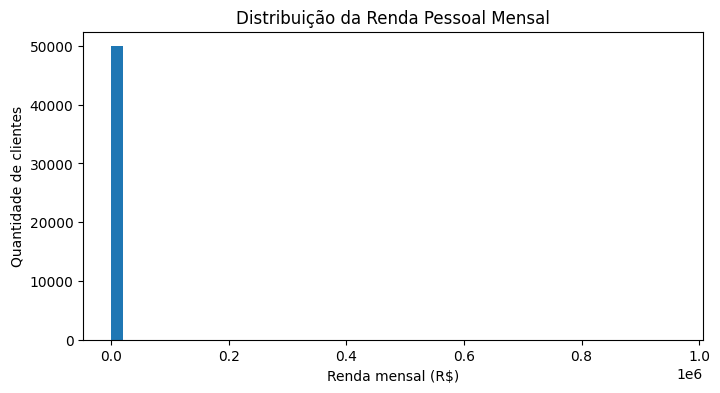

In [46]:
import matplotlib.pyplot as plt

# Histograma da renda mensal
plt.figure(figsize=(8, 4))

plt.hist(df["RENDA_PESSOAL_MENSAL"], bins=50)

plt.title("Distribuição da Renda Pessoal Mensal")
plt.xlabel("Renda mensal (R$)")
plt.ylabel("Quantidade de clientes")

plt.show()

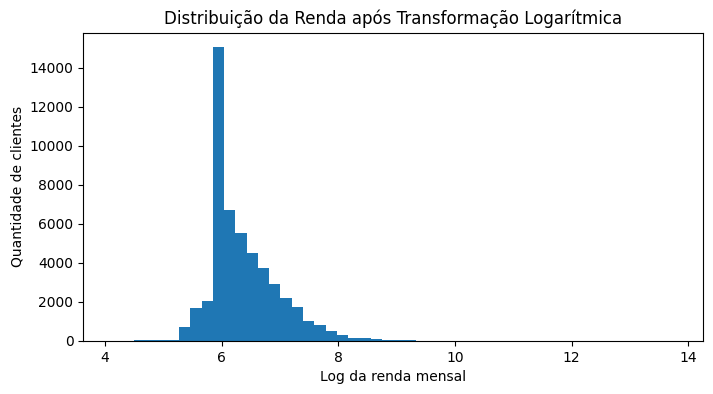

In [47]:
import numpy as np

# Criar uma nova variável com a renda transformada
df["LOG_RENDA"] = np.log1p(df["RENDA_PESSOAL_MENSAL"])

# Visualizar a nova distribuição
plt.figure(figsize=(8, 4))

plt.hist(df["LOG_RENDA"], bins=50)

plt.title("Distribuição da Renda após Transformação Logarítmica")
plt.xlabel("Log da renda mensal")
plt.ylabel("Quantidade de clientes")

plt.show()

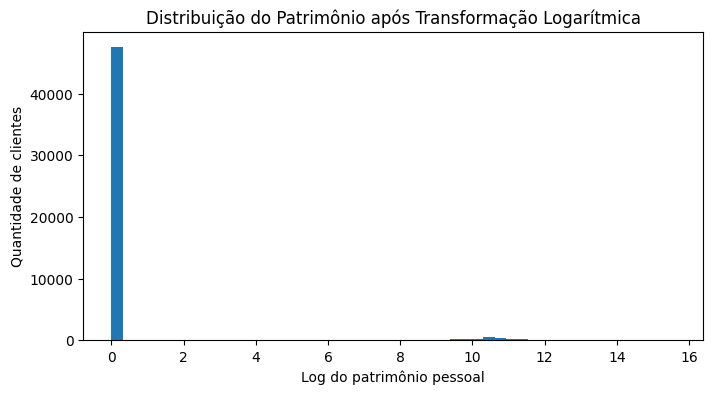

In [48]:
# Criar variável de patrimônio transformada
df["LOG_PATRIMONIO"] = np.log1p(df["VALOR_PATRIMONIO_PESSOAL"])

# Visualizar a distribuição
plt.figure(figsize=(8, 4))

plt.hist(df["LOG_PATRIMONIO"], bins=50)

plt.title("Distribuição do Patrimônio após Transformação Logarítmica")
plt.xlabel("Log do patrimônio pessoal")
plt.ylabel("Quantidade de clientes")

plt.show()

In [49]:
# Percentual de clientes com patrimônio igual a zero
percentual_zero = (df["VALOR_PATRIMONIO_PESSOAL"] == 0).mean() * 100

print(f"Clientes com patrimônio zero: {percentual_zero:.2f}%")

Clientes com patrimônio zero: 95.22%


In [50]:
# Criar indicador de patrimônio positivo
df["POSSUI_PATRIMONIO"] = (
    df["VALOR_PATRIMONIO_PESSOAL"] > 0
).astype(int)

# Verificar a distribuição
print(df["POSSUI_PATRIMONIO"].value_counts(normalize=True) * 100)

POSSUI_PATRIMONIO
0   95.22
1    4.78
Name: proportion, dtype: float64


In [51]:
# Taxa de inadimplência por grupo
taxa_inadimplencia = (
    df.groupby("POSSUI_PATRIMONIO")["ROTULO_ALVO_MAU"]
    .mean() * 100
)

print(taxa_inadimplencia.round(2))

POSSUI_PATRIMONIO
0   26.18
1   24.22
Name: ROTULO_ALVO_MAU, dtype: float64


In [52]:
# Mediana da renda por classificação de risco
renda_por_grupo = df.groupby("ROTULO_ALVO_MAU")[
    "RENDA_PESSOAL_MENSAL"
].median()

print(renda_por_grupo)

ROTULO_ALVO_MAU
0   500.00
1   500.00
Name: RENDA_PESSOAL_MENSAL, dtype: float64


In [53]:
# Estatísticas da renda por grupo de inadimplência
comparacao_renda = df.groupby("ROTULO_ALVO_MAU")[
    "RENDA_PESSOAL_MENSAL"
].describe()

# Selecionar as principais estatísticas
display(
    comparacao_renda[["mean", "25%", "50%", "75%"]].round(2)
)

,mean,25%,50%,75%
ROTULO_ALVO_MAU,,,,
0,873.54,360.00,500.00,800.00
1,923.91,360.00,500.00,800.00


In [54]:
# Comparar as duas variáveis
iguais = (
    df["QUANT_CONTAS_BANCARIAS"]
    == df["QUANT_CONTAS_BANCARIAS_ESPECIAIS"]
).all()

print("As duas variáveis são idênticas?", iguais)

As duas variáveis são idênticas? True


In [55]:
# Remover a variável redundante
df = df.drop(columns=["QUANT_CONTAS_BANCARIAS_ESPECIAIS"])

# Conferir as dimensões
print("Dimensões:", df.shape)

Dimensões: (50000, 47)


In [56]:
from sklearn.model_selection import train_test_split

# Separar variáveis explicativas e variável-alvo
X = df.drop(columns=["ID_CLIENTE", "ROTULO_ALVO_MAU"])
y = df["ROTULO_ALVO_MAU"]

# Separar treino e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Treino:", X_treino.shape)
print("Teste:", X_teste.shape)

Treino: (35000, 45)
Teste: (15000, 45)


In [57]:
# Identificar colunas numéricas com valores ausentes
colunas_nulas = X_treino.select_dtypes(
    include="number"
).columns

colunas_nulas = [
    coluna for coluna in colunas_nulas
    if X_treino[coluna].isnull().any()
]

# Calcular medianas apenas no treino
medianas = X_treino[colunas_nulas].median()

# Preencher treino e teste com as mesmas medianas
X_treino[colunas_nulas] = X_treino[colunas_nulas].fillna(medianas)
X_teste[colunas_nulas] = X_teste[colunas_nulas].fillna(medianas)

print("Variáveis tratadas:")
print(colunas_nulas)

print("\nValores ausentes restantes no treino:")
print(X_treino.isnull().sum().sum())

Variáveis tratadas:
['TIPO_RESIDENCIA', 'MESES_RESIDENCIA', 'CODIGO_PROFISSAO', 'TIPO_OCUPACAO', 'CODIGO_PROFISSAO_CONJUGE', 'NIVEL_EDUCACIONAL_CONJUGE']

Valores ausentes restantes no treino:
47434


In [58]:
# Identificar colunas categóricas
colunas_categoricas = X_treino.select_dtypes(
    include="object"
).columns

# Preencher valores ausentes
X_treino[colunas_categoricas] = (
    X_treino[colunas_categoricas].fillna("DESCONHECIDO")
)

X_teste[colunas_categoricas] = (
    X_teste[colunas_categoricas].fillna("DESCONHECIDO")
)

# Conferir valores ausentes
print("Nulos no treino:", X_treino.isnull().sum().sum())
print("Nulos no teste:", X_teste.isnull().sum().sum())

Nulos no treino: 0
Nulos no teste: 0


In [59]:
# Contar categorias distintas no conjunto de treino
cardinalidade = (
    X_treino.select_dtypes(include="object")
    .nunique()
    .sort_values(ascending=False)
)

display(cardinalidade)

,0
BAIRRO_RESIDENCIAL,11523
CIDADE_NASCIMENTO,8069
BAIRRO_PROFISSIONAL,3913
CIDADE_RESIDENCIAL,3037
CIDADE_PROFISSIONAL,1879
CEP_PROFISSIONAL_3,1431
CEP_RESIDENCIAL_3,1431
CODIGO_AREA_TELEFONE_RESIDENCIAL,94
CODIGO_AREA_TELEFONE_PROFISSIONAL,82
ESTADO_NASCIMENTO,29


In [60]:
# Identificar variáveis com mais de 30 categorias
alta_cardinalidade = cardinalidade[cardinalidade > 30]

# Identificar variáveis com até 30 categorias
baixa_cardinalidade = cardinalidade[cardinalidade <= 30]

print("Alta cardinalidade:")
print(alta_cardinalidade)

print("\nQuantidade de variáveis:")
print("Alta:", len(alta_cardinalidade))
print("Baixa:", len(baixa_cardinalidade))

Alta cardinalidade:
BAIRRO_RESIDENCIAL                   11523
CIDADE_NASCIMENTO                     8069
BAIRRO_PROFISSIONAL                   3913
CIDADE_RESIDENCIAL                    3037
CIDADE_PROFISSIONAL                   1879
CEP_PROFISSIONAL_3                    1431
CEP_RESIDENCIAL_3                     1431
CODIGO_AREA_TELEFONE_RESIDENCIAL        94
CODIGO_AREA_TELEFONE_PROFISSIONAL       82
dtype: int64

Quantidade de variáveis:
Alta: 9
Baixa: 8


In [61]:
# Comparar os CEPs residencial e profissional
iguais = (
    X_treino["CEP_RESIDENCIAL_3"]
    == X_treino["CEP_PROFISSIONAL_3"]
).all()

print("Os CEPs são idênticos?", iguais)

Os CEPs são idênticos? True


In [62]:
# Confirmar igualdade no conjunto de teste
iguais_teste = (
    X_teste["CEP_RESIDENCIAL_3"]
    == X_teste["CEP_PROFISSIONAL_3"]
).all()

print("CEPs idênticos no teste?", iguais_teste)

# Remover a coluna duplicada, caso sejam iguais
if iguais_teste:
    X_treino = X_treino.drop(columns=["CEP_PROFISSIONAL_3"])
    X_teste = X_teste.drop(columns=["CEP_PROFISSIONAL_3"])

print("Treino:", X_treino.shape)
print("Teste:", X_teste.shape)

CEPs idênticos no teste? True
Treino: (35000, 44)
Teste: (15000, 44)


In [64]:
# Criar variáveis dummy para SEXO
dummies_treino = pd.get_dummies(X_treino["SEXO"], dtype=int)
dummies_teste = pd.get_dummies(X_teste["SEXO"], dtype=int)

# Manter no teste as mesmas colunas do treino
dummies_teste = dummies_teste.reindex(
    columns=dummies_treino.columns,
    fill_value=0
)

print("Categorias encontradas:")
print(dummies_treino.columns.tolist())

display(dummies_treino.head())

Categorias encontradas:
[' ', 'F', 'M', 'N']


,,F,M,N
20112,0,0,1,0
44273,0,1,0,0
43621,0,1,0,0
24865,0,1,0,0
3089,0,1,0,0


In [65]:
# Contar registros por categoria, incluindo espaços em branco
print(
    X_treino["SEXO"].value_counts(dropna=False)
)

SEXO
F    21582
M    13378
N       26
        14
Name: count, dtype: int64


In [66]:
# Substituir espaços em branco por DESCONHECIDO
X_treino["SEXO"] = X_treino["SEXO"].replace(
    r"^\s*$", "DESCONHECIDO", regex=True
)

X_teste["SEXO"] = X_teste["SEXO"].replace(
    r"^\s*$", "DESCONHECIDO", regex=True
)

# Verificar as categorias após o tratamento
print(X_treino["SEXO"].value_counts())

SEXO
F               21582
M               13378
N                  26
DESCONHECIDO       14
Name: count, dtype: int64


In [67]:
# Criar variáveis dummy
dummies_treino = pd.get_dummies(
    X_treino["SEXO"], prefix="SEXO", dtype=int
)

dummies_teste = pd.get_dummies(
    X_teste["SEXO"], prefix="SEXO", dtype=int
)

# Garantir as mesmas colunas no treino e no teste
dummies_teste = dummies_teste.reindex(
    columns=dummies_treino.columns,
    fill_value=0
)

# Substituir a coluna original pelas variáveis dummy
X_treino = pd.concat(
    [X_treino.drop(columns=["SEXO"]), dummies_treino],
    axis=1
)

X_teste = pd.concat(
    [X_teste.drop(columns=["SEXO"]), dummies_teste],
    axis=1
)

print("Treino:", X_treino.shape)
print("Teste:", X_teste.shape)
print("\nVariáveis criadas:")
print(dummies_treino.columns.tolist())

Treino: (35000, 47)
Teste: (15000, 47)

Variáveis criadas:
['SEXO_DESCONHECIDO', 'SEXO_F', 'SEXO_M', 'SEXO_N']


In [68]:
# Contar categorias das variáveis de texto restantes
categorias_restantes = (
    X_treino.select_dtypes(include="object")
    .nunique()
    .sort_values()
)

display(categorias_restantes)

,0
FLAG_TELEFONE_RESIDENCIAL,2
EMPRESA,2
FLAG_TELEFONE_PROFISSIONAL,2
TIPO_ENVIO_APLICACAO,3
ESTADO_RESIDENCIAL,27
ESTADO_PROFISSIONAL,28
ESTADO_NASCIMENTO,29
CODIGO_AREA_TELEFONE_PROFISSIONAL,82
CODIGO_AREA_TELEFONE_RESIDENCIAL,94
CEP_RESIDENCIAL_3,1431


In [69]:
# Selecionar variáveis com até 30 categorias
colunas_dummy = categorias_restantes[
    categorias_restantes <= 30
].index.tolist()

# Criar variáveis dummy
X_treino = pd.get_dummies(
    X_treino,
    columns=colunas_dummy,
    dtype=int
)

X_teste = pd.get_dummies(
    X_teste,
    columns=colunas_dummy,
    dtype=int
)

# Alinhar as colunas do teste às do treino
X_teste = X_teste.reindex(
    columns=X_treino.columns,
    fill_value=0
)

print("Variáveis transformadas:", colunas_dummy)
print("\nTreino:", X_treino.shape)
print("Teste:", X_teste.shape)

Variáveis transformadas: ['FLAG_TELEFONE_RESIDENCIAL', 'EMPRESA', 'FLAG_TELEFONE_PROFISSIONAL', 'TIPO_ENVIO_APLICACAO', 'ESTADO_RESIDENCIAL', 'ESTADO_PROFISSIONAL', 'ESTADO_NASCIMENTO']

Treino: (35000, 133)
Teste: (15000, 133)


In [70]:
# Identificar as variáveis de texto restantes
alta_cardinalidade = X_treino.select_dtypes(
    include="object"
).columns.tolist()

# Remover essas variáveis da primeira versão
X_treino = X_treino.drop(columns=alta_cardinalidade)
X_teste = X_teste.drop(columns=alta_cardinalidade)

print("Variáveis removidas:", alta_cardinalidade)
print("\nTreino:", X_treino.shape)
print("Teste:", X_teste.shape)

Variáveis removidas: ['CIDADE_NASCIMENTO', 'CIDADE_RESIDENCIAL', 'BAIRRO_RESIDENCIAL', 'CODIGO_AREA_TELEFONE_RESIDENCIAL', 'CIDADE_PROFISSIONAL', 'BAIRRO_PROFISSIONAL', 'CODIGO_AREA_TELEFONE_PROFISSIONAL', 'CEP_RESIDENCIAL_3']

Treino: (35000, 125)
Teste: (15000, 125)


In [71]:
from sklearn.preprocessing import MinMaxScaler

# Criar o escalonador
scaler = MinMaxScaler(feature_range=(0, 1))

# Ajustar no treino e aplicar aos dois conjuntos
X_treino_scaled = scaler.fit_transform(X_treino)
X_teste_scaled = scaler.transform(X_teste)

print("Treino:", X_treino_scaled.shape)
print("Teste:", X_teste_scaled.shape)

Treino: (35000, 125)
Teste: (15000, 125)


In [72]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Criar o modelo
modelo = LogisticRegression(max_iter=1000)

# Treinar com os dados de treino
modelo.fit(X_treino_scaled, y_treino)

# Realizar previsões no conjunto de teste
y_prev = modelo.predict(X_teste_scaled)

# Avaliar a acurácia
acuracia = accuracy_score(y_teste, y_prev)

print(f"Acurácia: {acuracia:.2%}")

Acurácia: 73.87%


In [73]:
from sklearn.metrics import classification_report, confusion_matrix

# Relatório de classificação
print("Relatório de classificação:")
print(classification_report(y_teste, y_prev))

# Matriz de confusão
print("\nMatriz de confusão:")
print(confusion_matrix(y_teste, y_prev))

Relatório de classificação:
              precision    recall  f1-score   support

           0       0.74      1.00      0.85     11088
           1       0.44      0.01      0.01      3912

    accuracy                           0.74     15000
   macro avg       0.59      0.50      0.43     15000
weighted avg       0.66      0.74      0.63     15000


Matriz de confusão:
[[11055    33]
 [ 3886    26]]


In [74]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

# Criar e treinar a Árvore de Decisão
arvore = DecisionTreeClassifier(random_state=42)

arvore.fit(X_treino_scaled, y_treino)

# Realizar previsões
y_prev_arvore = arvore.predict(X_teste_scaled)

# Avaliar o modelo
print(classification_report(y_teste, y_prev_arvore))

              precision    recall  f1-score   support

           0       0.76      0.74      0.75     11088
           1       0.31      0.32      0.31      3912

    accuracy                           0.63     15000
   macro avg       0.53      0.53      0.53     15000
weighted avg       0.64      0.63      0.64     15000



In [75]:
from sklearn.ensemble import RandomForestClassifier

# Criar e treinar o modelo
floresta = RandomForestClassifier(random_state=42)

floresta.fit(X_treino_scaled, y_treino)

# Realizar previsões
y_prev_floresta = floresta.predict(X_teste_scaled)

# Avaliar o desempenho
print(classification_report(y_teste, y_prev_floresta))

              precision    recall  f1-score   support

           0       0.74      0.98      0.85     11088
           1       0.43      0.04      0.08      3912

    accuracy                           0.74     15000
   macro avg       0.59      0.51      0.46     15000
weighted avg       0.66      0.74      0.65     15000



In [76]:
# Importância das características na Árvore de Decisão
importancias = pd.Series(
    arvore.feature_importances_,
    index=X_treino.columns
)

# Mostrar as 10 características mais importantes
display(importancias.sort_values(ascending=False).head(10))

,0
IDADE,0.11
MESES_RESIDENCIA,0.09
RENDA_PESSOAL_MENSAL,0.09
LOG_RENDA,0.08
DIA_PAGAMENTO,0.05
TIPO_OCUPACAO,0.04
QUANT_DEPENDENTES,0.03
ESTADO_CIVIL,0.03
CODIGO_PROFISSAO,0.02
TIPO_RESIDENCIA,0.02


In [77]:
# Características criadas no projeto
novas_features = [
    "LOG_RENDA",
    "LOG_PATRIMONIO",
    "POSSUI_PATRIMONIO"
]

# Criar uma versão sem essas características
X_treino_sem_fe = X_treino.drop(columns=novas_features)
X_teste_sem_fe = X_teste.drop(columns=novas_features)

# Aplicar Min-Max sem utilizar informações do teste
scaler_sem_fe = MinMaxScaler()

X_treino_sem_fe = scaler_sem_fe.fit_transform(X_treino_sem_fe)
X_teste_sem_fe = scaler_sem_fe.transform(X_teste_sem_fe)

# Treinar Árvore de Decisão
arvore_sem_fe = DecisionTreeClassifier(random_state=42)
arvore_sem_fe.fit(X_treino_sem_fe, y_treino)

# Avaliar
y_prev_sem_fe = arvore_sem_fe.predict(X_teste_sem_fe)

print(classification_report(y_teste, y_prev_sem_fe))

              precision    recall  f1-score   support

           0       0.75      0.74      0.75     11088
           1       0.30      0.31      0.31      3912

    accuracy                           0.63     15000
   macro avg       0.53      0.53      0.53     15000
weighted avg       0.64      0.63      0.63     15000



In [78]:
from sklearn.metrics import confusion_matrix

print("SEM Feature Engineering:")
print(confusion_matrix(y_teste, y_prev_sem_fe))

print("\nCOM Feature Engineering:")
print(confusion_matrix(y_teste, y_prev_arvore))

SEM Feature Engineering:
[[8247 2841]
 [2682 1230]]

COM Feature Engineering:
[[8223 2865]
 [2648 1264]]


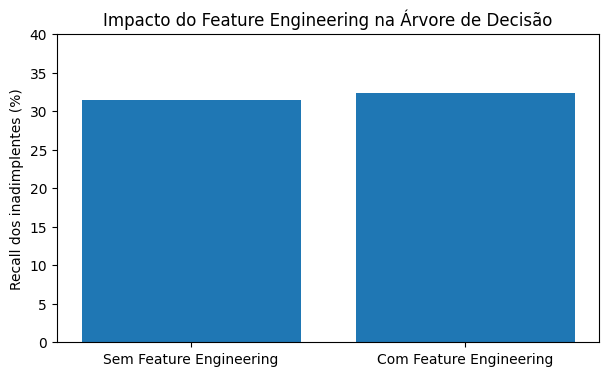

In [79]:
import matplotlib.pyplot as plt
from sklearn.metrics import recall_score

# Calcular recall da classe inadimplente
recall_sem = recall_score(y_teste, y_prev_sem_fe)
recall_com = recall_score(y_teste, y_prev_arvore)

# Comparar os resultados
plt.figure(figsize=(7, 4))

plt.bar(
    ["Sem Feature Engineering", "Com Feature Engineering"],
    [recall_sem * 100, recall_com * 100]
)

plt.ylabel("Recall dos inadimplentes (%)")
plt.title("Impacto do Feature Engineering na Árvore de Decisão")
plt.ylim(0, 40)

plt.show()

In [80]:
from sklearn.metrics import f1_score

f1_sem = f1_score(y_teste, y_prev_sem_fe)
f1_com = f1_score(y_teste, y_prev_arvore)

print(f"F1-score sem Feature Engineering: {f1_sem:.4f}")
print(f"F1-score com Feature Engineering: {f1_com:.4f}")
print(f"Diferença: {f1_com - f1_sem:+.4f}")

F1-score sem Feature Engineering: 0.3082
F1-score com Feature Engineering: 0.3144
Diferença: +0.0062


In [81]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

resultados = pd.DataFrame({
    "Modelo": ["Sem Feature Engineering", "Com Feature Engineering"],
    "Acurácia": [
        accuracy_score(y_teste, y_prev_sem_fe),
        accuracy_score(y_teste, y_prev_arvore)
    ],
    "Precision": [
        precision_score(y_teste, y_prev_sem_fe),
        precision_score(y_teste, y_prev_arvore)
    ],
    "Recall": [
        recall_score(y_teste, y_prev_sem_fe),
        recall_score(y_teste, y_prev_arvore)
    ],
    "F1-score": [
        f1_score(y_teste, y_prev_sem_fe),
        f1_score(y_teste, y_prev_arvore)
    ]
})

display(resultados.round(4))

,Modelo,Acurácia,Precision,Recall,F1-score
0,Sem Feature Engineering,0.63,0.30,0.31,0.31
1,Com Feature Engineering,0.63,0.31,0.32,0.31
